<a href="https://colab.research.google.com/github/iitianpriyanshu2006-blip/Era5-heatwave-forecasting/blob/main/Heatwave_Forecasting_Using_ERA5_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install xarray

import xarray as xr

In [4]:
import xarray as xr

files = {
    "wind": "/content/drive/MyDrive/Colab Notebooks/windspeed.nc",
    "temp": "/content/drive/MyDrive/Colab Notebooks/temperature.nc",
    "rain": "/content/drive/MyDrive/Colab Notebooks/rainfall.nc",
    "pres": "/content/drive/MyDrive/Colab Notebooks/pressure.nc",
    "hum": "/content/drive/MyDrive/Colab Notebooks/humidity.nc"
}

for name, path in files.items():
    ds = xr.open_dataset(path)
    print(f"\n{name}")
    print(ds.dims)
    print(ds.coords)
    print(ds.data_vars)



wind
FrozenMappingWarningOnValuesAccess({'time': 324, 'latitude': 121, 'longitude': 121})
Coordinates:
  * time       (time) datetime64[ns] 3kB 1998-01-01 1998-02-01 ... 2024-12-01
  * latitude   (latitude) float64 968B 37.0 36.75 36.5 36.25 ... 7.5 7.25 7.0
  * longitude  (longitude) float64 968B 68.0 68.25 68.5 ... 97.5 97.75 98.0
Data variables:
    ws       (time, latitude, longitude) float32 19MB ...

temp
FrozenMappingWarningOnValuesAccess({'time': 324, 'latitude': 121, 'longitude': 121})
Coordinates:
  * time       (time) datetime64[ns] 3kB 1998-01-01 1998-02-01 ... 2024-12-01
  * latitude   (latitude) float64 968B 37.0 36.75 36.5 36.25 ... 7.5 7.25 7.0
  * longitude  (longitude) float64 968B 68.0 68.25 68.5 ... 97.5 97.75 98.0
    number     int64 8B ...
    expver     (time) <U4 5kB ...
Data variables:
    t2m      (time, latitude, longitude) float32 19MB ...

rain
FrozenMappingWarningOnValuesAccess({'time': 324, 'bnds': 2, 'latitude': 121, 'longitude': 121})
Coordinates:
  *

In [5]:
!pip install -q xarray netcdf4
"""
Corrected data-preparation cells for the heatwave forecasting notebook.

WHY: the five ERA5 files carry different timestamp conventions for the same month
(e.g. 1st-of-month 00:00 vs mid-month 11:00/22:30). xr.merge() therefore built an
outer-joined time axis with 972 steps instead of 324 (27 years x 12 months); 2/3 of
every variable was NaN and was then filled with the global mean, producing constant
maps. This file replaces: the xr.merge cell, the fillna(df.mean()) cell, and the
heatwave-label cell.
"""
import numpy as np
import pandas as pd
import xarray as xr

DROP = ["time_bnds", "valid_time_bnds", "number", "expver", "bnds"]


def load_variable(path, rename=None):
    """Open one file and snap its timestamps to the first day of the month."""
    ds = xr.open_dataset(path)
    ds = ds.drop_vars([v for v in DROP if v in ds.variables])
    months = ds.indexes["time"].to_period("M").to_timestamp()
    ds = ds.assign_coords(time=months)
    ds = ds.groupby("time").first()          # collapse duplicate months (e.g. ERA5 vs ERA5T)
    if rename:
        ds = ds.rename(rename)
    return ds


def build_dataset(paths):
    """paths: dict like {'wind': (path, {'ws': 'windspeed'}), ...}"""
    parts = [load_variable(p, r) for p, r in paths.values()]
    ds = xr.merge(parts, join="inner")       # inner join: keep only months present in ALL files
    n_months = ds.sizes["time"]
    assert not ds.to_array().isnull().any(), "NaNs remain - check the source files"
    print(f"{n_months} monthly steps, {ds.time.values[0]} -> {ds.time.values[-1]}")
    return ds


def make_heatwave_label(ds, train_frac=0.70, q=0.90):
    """'Extreme-heat month' label: per grid cell and per calendar month, temperature above the
    q-quantile of the TRAINING period only (no leakage from validation/test).
    With ~19 training years there are only ~19 samples per calendar month, so q=0.90 is more stable than 0.95."""
    t_c = ds["temperature"] - 273.15
    n_train = int(train_frac * ds.sizes["time"])
    train = t_c.isel(time=slice(0, n_train))
    thresh = train.groupby("time.month").quantile(q, dim="time")      # (month, lat, lon)
    thresh_t = thresh.sel(month=t_c["time"].dt.month).drop_vars("month")
    label = (t_c > thresh_t.values).astype("int8")
    return t_c.rename("temperature_c"), label.rename("heatwave")



# ---------------- RUN: build the dataset used by the rest of the notebook ----------------
base = "/content/drive/MyDrive/Colab Notebooks/"
paths = {
    "wind": (base + "windspeed.nc",   {"ws":  "windspeed"}),
    "temp": (base + "temperature.nc", {"t2m": "temperature"}),
    "rain": (base + "rainfall.nc",    {"tp":  "rainfall"}),
    "pres": (base + "pressure.nc",    {"msl": "pressure"}),
    "hum":  (base + "humidity.nc",    {"rh":  "humidity"}),
}
ds = build_dataset(paths).load()          # expect: 324 monthly steps, no NaNs
t_c, label = make_heatwave_label(ds)      # label from TRAINING period only
ds["temperature_c"] = t_c
ds["heatwave"] = label
print(ds)
print("Event share (all months): %.2f%%" % (100 * float(ds["heatwave"].mean())))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 111.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 92.0 MB/s eta 0:00:00
324 monthly steps, 1998-01-01T00:00:00.000000000 -> 2024-12-01T00:00:00.000000000
<xarray.Dataset> Size: 119MB
Dimensions:        (time: 324, latitude: 121, longitude: 121)
Coordinates:
  * time           (time) datetime64[ns] 3kB 1998-01-01 ... 2024-12-01
  * latitude       (latitude) float64 968B 37.0 36.75 36.5 ... 7.5 7.25 7.0
  * longitude      (longitude) float64 968B 68.0 68.25 68.5 ... 97.5 97.75 98.0
Data variables:
    windspeed      (time, latitude, longitude) float32 19MB 0.7662 ... 4.501
    temperature    (time, latitude, longitude) float32 19MB 277.4 ... 300.7
    rainfall       (time, latitude, longitude) float32 19MB 0.04807 ... 0.1722
    pressure       (time, latitude, longitude) float32 19MB 1.022e+05 ... 1.0...
    humidity       (time, latitude, longitude) float32 19MB 84.81 ... 79.82
    temperature_c  (time,

In [6]:
# import xarray as xr

# ds = xr.open_dataset("/content/drive/MyDrive/Colab Notebooks/climate_finaldata.nc")
# # print(ds)

# ds["temperature_c"]= ds["temperature"]-273.15

# print(ds["temperature_c"])

# # print(ds["temperature_c"].min().values)
# # print(ds["temperature_c"].max().values)


# #CREATE HEATWAVE LABEL

# heatwave_threshold = ds["temperature_c"].quantile(0.95)
# print("Heatwave Threshold:",float(heatwave_threshold.values))

# ds["heatwave"] = (ds["temperature_c"] >= heatwave_threshold).astype(int)

# # print(ds["heatwave"])

# heatwave_percent = ds["heatwave"].mean().values * 100
# print("Heatwave Percentage:",float(heatwave_percent))

# ds["heatwave"]= (ds["temperature_c"] > heatwave_threshold).astype(int)

# # print(ds["heatwave"])

# print(ds["heatwave"].sum().values)
# print(ds["heatwave"].mean().values *100)

# # ds.to_netcdf("/content/drive/MyDrive/Colab Notebooks/climate_maindataset_heatwave.nc")


In [7]:
# import xarray as xr

# ds = xr.open_dataset("/content/drive/MyDrive/Colab Notebooks/climate_maindataset_heatwave.nc")

# # FEATURE EXTRACTION

# features =[
#     "temperature_c",
#     "humidity",
#     "pressure",
#     "rainfall",
#     "windspeed"
# ]

# target = "heatwave"

# df = ds.to_dataframe().reset_index()
# # print(df.shape)
# # print(df.isnull().sum())

# # x =df[features]
# # y =df[target]

# # print(y.value_counts())
# # print(y.value_counts(normalize=True)*100)

# # print(x.head())
# # print(y.head())

# # from sklearn.model_selection import train_test_split

# # x_train, x_test, y_train, y_test = train_test_split(
# #     x,
# #     y,
# #     test_size=0.2,
# #     random_state=42,
# #     stratify=y
# # )

# # print(x_train.shape)
# # print(x_test.shape)
# # print(y_train.shape)
# # print(y_test.shape)

# # print(x.head())
# # print(y.head())

# # print(y_train.value_counts())

# # The print(y.value_counts()) was duplicated, keeping the first one
# # print(ds.variables)

In [8]:
# # SORTING THR DATA  /////////////////////////////////////////////////////////////////////////////////////////
# import pandas as pd
# df = df.sort_values(["time","latitude","time"])
# # print(df.head())



# # CREATE LAG FEATURES ///////////////////////////////////////////////////////////////
# features = [
#     "temperature_c",
#     "humidity",
#     "pressure",
#     "rainfall",
#     "windspeed"
# ]

# lookback = 7

# for feature in features:
#   for lag in range(1,lookback+1):
#     df[f"{feature}_lag_{lag}"] =( df.groupby(["latitude","longitude"])[feature].shift(lag))

# # print(df.head())

#     # REMOVE MISSING VALUES//////////////////////////////////////////////////////////

# # df = df.dropna().reset_index(drop=True)

# # DEFINE X AND Y ////////////////////////////////////////////////////////////////////

# # lag_columns = [col for col in df.columns if "lag" in col]

# # x = df[lag_columns]
# # y = df["heatwave"]




**COMPARING MODELS**

In [9]:
#DEFINE THE SPLIT ########################################
# Total number of time steps
n_time = ds.sizes["time"]

# 70% Train, 15% Validation, 15% Test
train_end = int(0.70 * n_time)
val_end = int(0.85 * n_time)

print("Total Time Steps :", n_time)
print("Train End Index  :", train_end)
print("Validation End   :", val_end)

Total Time Steps : 324
Train End Index  : 226
Validation End   : 275


In [11]:
#SPLIT THE DATASET BY TIME #################################
train_ds = ds.isel(time=slice(0, train_end))
val_ds = ds.isel(time=slice(train_end, val_end))
test_ds = ds.isel(time=slice(val_end, n_time))

In [12]:
# VERIFY THE SPLIT #######################################
print("Training Dataset")
print(train_ds)

print("\nValidation Dataset")
print(val_ds)

print("\nTesting Dataset")
print(test_ds)

Training Dataset
<xarray.Dataset> Size: 83MB
Dimensions:        (time: 226, latitude: 121, longitude: 121)
Coordinates:
  * time           (time) datetime64[ns] 2kB 1998-01-01 ... 2016-10-01
  * latitude       (latitude) float64 968B 37.0 36.75 36.5 ... 7.5 7.25 7.0
  * longitude      (longitude) float64 968B 68.0 68.25 68.5 ... 97.5 97.75 98.0
Data variables:
    windspeed      (time, latitude, longitude) float32 13MB 0.7662 ... 6.347
    temperature    (time, latitude, longitude) float32 13MB 277.4 ... 300.3
    rainfall       (time, latitude, longitude) float32 13MB 0.04807 ... 0.2116
    pressure       (time, latitude, longitude) float32 13MB 1.022e+05 ... 1.0...
    humidity       (time, latitude, longitude) float32 13MB 84.81 ... 83.69
    temperature_c  (time, latitude, longitude) float32 13MB 4.26 4.42 ... 27.16
    heatwave       (time, latitude, longitude) int8 3MB 0 0 0 0 0 ... 0 0 0 0 0
Attributes:
    CDI:                     Climate Data Interface version 2.0.4 (https://m

In [13]:
# VERIFY THE SPLIT ########################################
print("Train:", train_ds.sizes["time"])
print("Validation:", val_ds.sizes["time"])
print("Test:", test_ds.sizes["time"])

Train: 226
Validation: 49
Test: 49


In [14]:
# SELECT THE INPUT VARIABLES #############################
feature_vars = [
    "temperature",
    "humidity",
    "pressure",
    "rainfall",
    "windspeed"
]

In [15]:
# SEQUENCE CREATION FUNCTION ###########################
import numpy as np

def create_sequences(dataset, feature_vars, target_var="heatwave", seq_len=7):

    X = []
    y = []

    features = np.stack(
        [dataset[var].values for var in feature_vars],
        axis=-1
    )

    target = dataset[target_var].values

    for i in range(len(dataset.time) - seq_len):

        X.append(features[i:i+seq_len])

        y.append(target[i+seq_len])

    return np.array(X), np.array(y)

In [16]:
# CREATE SEQUENCES ################################
X_train, y_train = create_sequences(train_ds, feature_vars)

X_val, y_val = create_sequences(val_ds, feature_vars)

X_test, y_test = create_sequences(test_ds, feature_vars)

In [17]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (219, 7, 121, 121, 5)
y_train: (219, 121, 121)
X_val: (42, 7, 121, 121, 5)
y_val: (42, 121, 121)
X_test: (42, 7, 121, 121, 5)
y_test: (42, 121, 121)


# Corrected architecture section

        The preceding dataset handling, Drive paths, random/demo heatwave labels,
        chronological split, and seven-day sequence construction are copied unchanged
        from the original notebook. The earlier duplicate and incompatible model cells
        were replaced by the five compatible architectures below.


In [18]:
# Run once.  This notebook needs no torch-geometric or third-party ConvLSTM package.
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import xarray as xr
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}; GPUs: {torch.cuda.device_count()}")


Device: cuda; GPUs: 1


## 2. Workflow and model-ready tensors


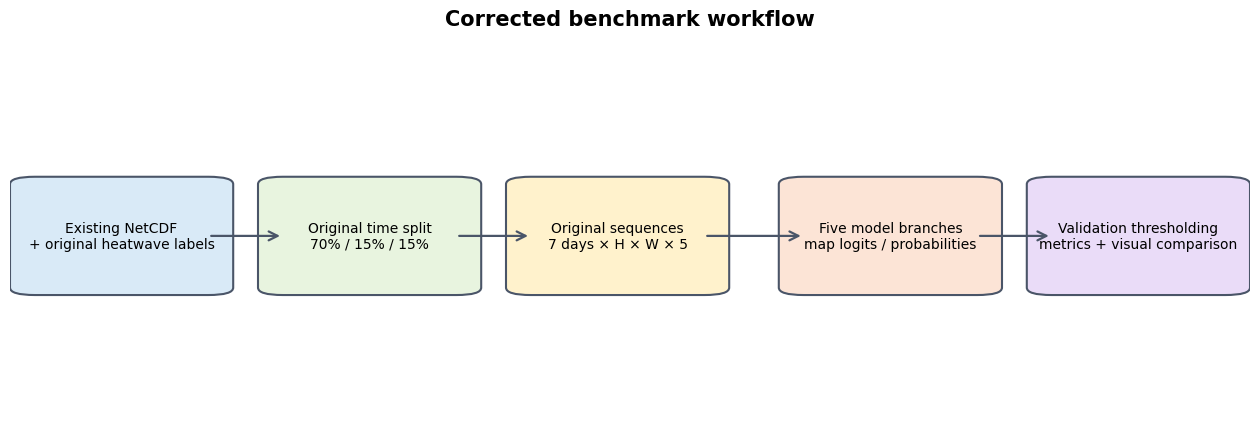

Model tensor shape: (N, 7, 5, 121, 121)


In [19]:
# Visual workflow: the data path is unchanged; every model receives the same sequences.
def draw_workflow():
    fig, ax = plt.subplots(figsize=(16, 4.8))
    ax.axis("off")
    nodes = [
        (0.02, "Existing NetCDF\n+ original heatwave labels", "#d9eaf7"),
        (0.22, "Original time split\n70% / 15% / 15%", "#e8f4df"),
        (0.42, "Original sequences\n7 days \u00d7 H \u00d7 W \u00d7 5", "#fff2cc"),
        (0.64, "Five model branches\nmap logits / probabilities", "#fce4d6"),
        (0.84, "Validation thresholding\nmetrics + visual comparison", "#eadcf8"),
    ]
    for x, label, color in nodes:
        patch = FancyBboxPatch((x, 0.35), 0.14, 0.28, boxstyle="round,pad=0.02",
                               facecolor=color, edgecolor="#4a5568", linewidth=1.5)
        ax.add_patch(patch)
        ax.text(x + 0.07, 0.49, label, ha="center", va="center", fontsize=10)
    for i in range(len(nodes) - 1):
        ax.add_patch(FancyArrowPatch((nodes[i][0] + 0.14, 0.49), (nodes[i + 1][0], 0.49),
                                     arrowstyle="->", mutation_scale=16, linewidth=1.6,
                                     color="#4a5568"))
    ax.set_title("Corrected benchmark workflow", fontsize=15, weight="bold", pad=16)
    plt.show()

draw_workflow()

# Model-side standardization is fitted on training inputs only.  It does not change
# the original samples, labels, sequence construction, or split.
feature_mean = X_train.mean(axis=(0, 1, 2, 3), keepdims=True).astype(np.float32)
feature_std = X_train.std(axis=(0, 1, 2, 3), keepdims=True).astype(np.float32)
feature_std = np.where(feature_std < 1e-6, 1.0, feature_std)

def make_tensor_dataset(X, y):
    X_scaled = ((X.astype(np.float32) - feature_mean) / feature_std)
    # Original format N,T,H,W,C -> model format N,T,C,H,W.
    X_tensor = torch.from_numpy(np.ascontiguousarray(X_scaled.transpose(0, 1, 4, 2, 3)))
    y_tensor = torch.from_numpy(y.astype(np.float32))
    return TensorDataset(X_tensor, y_tensor)

train_tensor_ds = make_tensor_dataset(X_train, y_train)
val_tensor_ds = make_tensor_dataset(X_val, y_val)
test_tensor_ds = make_tensor_dataset(X_test, y_test)

BATCH_SIZE = 2 if torch.cuda.is_available() else 1
train_loader = DataLoader(train_tensor_ds, batch_size=BATCH_SIZE, shuffle=True,
                          pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_tensor_ds, batch_size=BATCH_SIZE, shuffle=False,
                        pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_tensor_ds, batch_size=BATCH_SIZE, shuffle=False,
                         pin_memory=torch.cuda.is_available())

SEQUENCE_LENGTH = 7
_, _, N_FEATURES, HEIGHT, WIDTH = train_tensor_ds.tensors[0].shape
print(f"Model tensor shape: (N, {SEQUENCE_LENGTH}, {N_FEATURES}, {HEIGHT}, {WIDTH})")


## 3. Corrected architectures

- **Last value:** previous observed heatwave map, exactly aligned to each original sequence.
- **Climatology:** grid-cell heatwave frequency over training data only.
- **CNN:** spatialized version of the heatwave CNN in Jacques-Dumas et al. (2022):
  two 12×12 convolutions, 2×2 pooling, then two 9×9 convolutions.  The paper's scalar
  head is replaced by a 1×1 map head so it can forecast every grid cell.
- **ConvLSTM:** three sequential 3×3 ConvLSTM cells, each with 60 hidden channels,
  following the architecture family used in Pellicer-Valero et al. (2025), with a map head.
- **GCN-LSTM:** two shared 8-neighbour grid graph-convolution layers at every day, then
  a per-grid-cell LSTM over the seven-day spatial embeddings.


In [20]:
class PaperHeatwaveCNN(nn.Module):
    # Map-output adaptation of the 12x12/9x9 heatwave CNN.
    def __init__(self, sequence_length, n_features, dropout=0.25):
        super().__init__()
        in_channels = sequence_length * n_features
        self.conv1 = nn.Conv2d(in_channels, 32, kernel_size=12, padding="same")
        self.conv2 = nn.Conv2d(32, 32, kernel_size=12, padding="same")
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.dropout1 = nn.Dropout2d(dropout)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=9, padding="same")
        self.conv4 = nn.Conv2d(64, 64, kernel_size=9, padding="same")
        self.dropout2 = nn.Dropout2d(dropout)
        self.map_head = nn.Sequential(
            nn.Conv2d(64, 16, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(16, 1, kernel_size=1),
        )

    def forward(self, x):
        # x: B,T,C,H,W; flatten time and weather variables into input channels.
        b, t, c, h, w = x.shape
        x = x.reshape(b, t * c, h, w)
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.dropout1(self.pool(x))
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = self.dropout2(x)
        x = self.map_head(x)
        return F.interpolate(x, size=(h, w), mode="bilinear", align_corners=False).squeeze(1)


class ConvLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim, kernel_size=3):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.gates = nn.Conv2d(input_dim + hidden_dim, 4 * hidden_dim,
                               kernel_size=kernel_size, padding=kernel_size // 2)

    def forward(self, x, state):
        h, c = state
        i, f, o, g = torch.chunk(self.gates(torch.cat([x, h], dim=1)), 4, dim=1)
        i, f, o = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o)
        g = torch.tanh(g)
        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c


class ThreeLayerConvLSTM(nn.Module):
    # Three 3x3 ConvLSTM layers with 60 hidden channels each.
    def __init__(self, n_features, hidden_dim=60):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.cell1 = ConvLSTMCell(n_features, hidden_dim, 3)
        self.cell2 = ConvLSTMCell(hidden_dim, hidden_dim, 3)
        self.cell3 = ConvLSTMCell(hidden_dim, hidden_dim, 3)
        self.map_head = nn.Sequential(
            nn.Conv2d(hidden_dim, 10, kernel_size=1), nn.ReLU(inplace=True),
            nn.Conv2d(10, 1, kernel_size=1),
        )

    def _empty_state(self, batch, height, width, reference):
        z = reference.new_zeros(batch, self.hidden_dim, height, width)
        return z, z.clone()

    def forward(self, x):
        b, t, _, h, w = x.shape
        s1 = self._empty_state(b, h, w, x)
        s2 = self._empty_state(b, h, w, x)
        s3 = self._empty_state(b, h, w, x)
        for step in range(t):
            h1, c1 = self.cell1(x[:, step], s1)
            h2, c2 = self.cell2(h1, s2)
            h3, c3 = self.cell3(h2, s3)
            s1, s2, s3 = (h1, c1), (h2, c2), (h3, c3)
        return self.map_head(s3[0]).squeeze(1)


class GridGraphConv(nn.Module):
    # Shared 8-neighbour graph convolution on a regular HxW grid.
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.self_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.neighbour_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.bias = nn.Parameter(torch.zeros(1, out_channels, 1, 1))

    def forward(self, x):
        _, _, h, w = x.shape
        padded = F.pad(x, (1, 1, 1, 1), mode="replicate")
        neighbours = []
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if dy != 0 or dx != 0:
                    neighbours.append(padded[:, :, 1 + dy:1 + dy + h, 1 + dx:1 + dx + w])
        neighbour_mean = torch.stack(neighbours, dim=0).mean(dim=0)
        return self.self_linear(x) + self.neighbour_linear(neighbour_mean) + self.bias


class GCN_LSTM(nn.Module):
    # Two 8-neighbour graph layers per day, followed by an LSTM per grid cell.
    def __init__(self, n_features, gcn_hidden=32, lstm_hidden=64, dropout=0.25):
        super().__init__()
        self.gcn1 = GridGraphConv(n_features, gcn_hidden)
        self.gcn2 = GridGraphConv(gcn_hidden, gcn_hidden)
        self.dropout = nn.Dropout2d(dropout)
        self.lstm = nn.LSTM(gcn_hidden, lstm_hidden, batch_first=True)
        self.classifier = nn.Sequential(
            nn.Linear(lstm_hidden, 32), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        b, t, _, h, w = x.shape
        embeddings = []
        for step in range(t):
            z = F.relu(self.gcn1(x[:, step]))
            z = self.dropout(z)
            z = F.relu(self.gcn2(z))
            embeddings.append(z.permute(0, 2, 3, 1).reshape(b, h * w, -1))
        # B,N,T,F -> (B*N),T,F for a temporal model at every grid node.
        sequence = torch.stack(embeddings, dim=2).reshape(b * h * w, t, -1)
        last_state = self.lstm(sequence)[0][:, -1]
        return self.classifier(last_state).reshape(b, h, w)


# Shape checks catch incompatible edits before a long training run.
sample_x = train_tensor_ds.tensors[0][:1].to(device)
for name, model in {
    "CNN": PaperHeatwaveCNN(SEQUENCE_LENGTH, N_FEATURES),
    "ConvLSTM": ThreeLayerConvLSTM(N_FEATURES),
    "GCN-LSTM": GCN_LSTM(N_FEATURES),
}.items():
    with torch.no_grad():
        assert model.to(device)(sample_x).shape == (1, HEIGHT, WIDTH), name
    print(f"{name:9s} output shape verified: (B, {HEIGHT}, {WIDTH})")
del sample_x


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/conv.py:548: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /pytorch/aten/src/ATen/native/Convolution.cpp:1024.)
  return F.conv2d(


CNN       output shape verified: (B, 121, 121)
ConvLSTM  output shape verified: (B, 121, 121)
GCN-LSTM  output shape verified: (B, 121, 121)


## 4. Common training and evaluation


In [21]:
MAX_EPOCHS = 20          # Increase to 30 after a successful smoke run.
PATIENCE = 5
LEARNING_RATE = 1e-3

def safe_auc(metric_fn, truth, probabilities):
    try:
        return float(metric_fn(truth, probabilities))
    except ValueError:  # a split can contain one class in a very small experiment
        return float("nan")


def metrics_from_probabilities(y_true, probabilities, threshold):
    truth = np.asarray(y_true).reshape(-1).astype(np.uint8)
    prob = np.asarray(probabilities).reshape(-1)
    pred = (prob >= threshold).astype(np.uint8)
    return {
        "Accuracy": accuracy_score(truth, pred),
        "Precision": precision_score(truth, pred, zero_division=0),
        "Recall": recall_score(truth, pred, zero_division=0),
        "F1": f1_score(truth, pred, zero_division=0),
        "PR-AUC": safe_auc(average_precision_score, truth, prob),
        "ROC-AUC": safe_auc(roc_auc_score, truth, prob),
        "Threshold": float(threshold),
    }


def choose_validation_threshold(y_true, probabilities):
    candidates = np.arange(0.05, 0.96, 0.05)
    scores = [f1_score(np.asarray(y_true).reshape(-1),
                       (np.asarray(probabilities).reshape(-1) >= t).astype(np.uint8),
                       zero_division=0) for t in candidates]
    return float(candidates[int(np.argmax(scores))])


@torch.no_grad()
def predict_probabilities(model, loader):
    model.eval()
    probabilities, labels = [], []
    for X_batch, y_batch in loader:
        logits = model(X_batch.to(device, non_blocking=True))
        probabilities.append(torch.sigmoid(logits).cpu().numpy())
        labels.append(y_batch.numpy())
    return np.concatenate(probabilities), np.concatenate(labels)


def train_neural_model(name, model):
    model = model.to(device)
    if torch.cuda.device_count() > 1:
        model = nn.DataParallel(model)

    positives = float(y_train.sum())
    negatives = float(y_train.size - positives)
    pos_weight = torch.tensor([negatives / max(positives, 1.0)], device=device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )

    best_state, best_val_loss, stale_epochs = None, float("inf"), 0
    history = {"train_loss": [], "val_loss": []}
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        running_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            running_loss += loss.item() * X_batch.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device, non_blocking=True)
                y_batch = y_batch.to(device, non_blocking=True)
                running_val_loss += criterion(model(X_batch), y_batch).item() * X_batch.size(0)
        val_loss = running_val_loss / len(val_loader.dataset)
        scheduler.step(val_loss)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        print(f"{name:9s} | epoch {epoch:02d} | train {train_loss:.4f} | val {val_loss:.4f}")

        if val_loss < best_val_loss - 1e-5:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
            if stale_epochs >= PATIENCE:
                print(f"{name}: early stopping at epoch {epoch}")
                break

    model.load_state_dict(best_state)
    val_prob, val_truth = predict_probabilities(model, val_loader)
    threshold = choose_validation_threshold(val_truth, val_prob)
    split_scores = {}
    predictions = {}
    for split_name, loader in [("Training", train_loader), ("Validation", val_loader), ("Test", test_loader)]:
        prob, truth = predict_probabilities(model, loader)
        predictions[split_name] = (prob, truth)
        split_scores[split_name] = metrics_from_probabilities(truth, prob, threshold)
    return model, history, split_scores, predictions


## 5. Run all five models


In [22]:
# The two non-neural baselines use exactly the original target maps.
def persistence_predictions(dataset, target_var="heatwave", seq_len=SEQUENCE_LENGTH):
    target = dataset[target_var].values
    return target[seq_len - 1:-1].astype(np.float32), target[seq_len:].astype(np.float32)

all_scores, all_histories, saved_predictions, trained_models = {}, {}, {}, {}

last_value_sets = {}
for split_name, dataset in [("Training", train_ds), ("Validation", val_ds), ("Test", test_ds)]:
    prob, truth = persistence_predictions(dataset)
    last_value_sets[split_name] = (prob, truth)
all_scores["Last value"] = {
    split: metrics_from_probabilities(truth, prob, threshold=0.5)
    for split, (prob, truth) in last_value_sets.items()
}
saved_predictions["Last value"] = last_value_sets

climatology_probability = y_train.mean(axis=0).astype(np.float32)
climatology_sets = {
    "Training": (np.broadcast_to(climatology_probability, y_train.shape), y_train),
    "Validation": (np.broadcast_to(climatology_probability, y_val.shape), y_val),
    "Test": (np.broadcast_to(climatology_probability, y_test.shape), y_test),
}
climatology_threshold = choose_validation_threshold(*climatology_sets["Validation"][::-1])
all_scores["Climatology"] = {
    split: metrics_from_probabilities(truth, prob, climatology_threshold)
    for split, (prob, truth) in climatology_sets.items()
}
saved_predictions["Climatology"] = climatology_sets

neural_factories = {
    "CNN": lambda: PaperHeatwaveCNN(SEQUENCE_LENGTH, N_FEATURES),
    "ConvLSTM": lambda: ThreeLayerConvLSTM(N_FEATURES, hidden_dim=60),
    "GCN-LSTM": lambda: GCN_LSTM(N_FEATURES, gcn_hidden=32, lstm_hidden=64),
}
for model_name, factory in neural_factories.items():
    model, history, scores, predictions = train_neural_model(model_name, factory())
    trained_models[model_name] = model
    all_histories[model_name] = history
    all_scores[model_name] = scores
    saved_predictions[model_name] = predictions

comparison_results = pd.DataFrame([
    {"Model": name, "Split": split, **metrics}
    for name, score_by_split in all_scores.items()
    for split, metrics in score_by_split.items()
])
display(comparison_results.round(4).sort_values(["Split", "F1"], ascending=[True, False]))

CNN       | epoch 01 | train 1.3674 | val 2.0257
CNN       | epoch 02 | train 1.2464 | val 2.0166
CNN       | epoch 03 | train 1.2455 | val 2.0157
CNN       | epoch 04 | train 1.2453 | val 2.0103
CNN       | epoch 05 | train 1.2452 | val 2.0103
CNN       | epoch 06 | train 1.2452 | val 2.0095
CNN       | epoch 07 | train 1.2452 | val 2.0073
CNN       | epoch 08 | train 1.2452 | val 2.0064
CNN       | epoch 09 | train 1.2457 | val 2.0064
CNN       | epoch 10 | train 1.2450 | val 1.9995
CNN       | epoch 11 | train 1.2450 | val 1.9999
CNN       | epoch 12 | train 2.4937 | val 2.0534
CNN       | epoch 13 | train 1.2464 | val 2.0056
CNN       | epoch 14 | train 1.2450 | val 2.0034
CNN       | epoch 15 | train 1.2449 | val 2.0020
CNN: early stopping at epoch 15
ConvLSTM  | epoch 01 | train 1.2776 | val 2.2188
ConvLSTM  | epoch 02 | train 1.2649 | val 2.0672
ConvLSTM  | epoch 03 | train 1.2932 | val 2.2045
ConvLSTM  | epoch 04 | train 1.2612 | val 2.0519
ConvLSTM  | epoch 05 | train 1.2592 |

,Model,Split,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC,Threshold
2,Last value,Test,0.6933,0.5757,0.5647,0.5702,0.4819,0.6652,0.50
5,Climatology,Test,0.3602,0.3602,1.0000,0.5296,0.3289,0.4398,0.05
8,CNN,Test,0.3602,0.3602,1.0000,0.5296,0.3602,0.5000,0.05
14,GCN-LSTM,Test,0.3602,0.3602,1.0000,0.5296,0.3210,0.4394,0.05
11,ConvLSTM,Test,0.4145,0.3644,0.8403,0.5083,0.3421,0.4954,0.45
0,Last value,Training,0.8591,0.3100,0.3079,0.3090,0.1663,0.6149,0.50
3,Climatology,Training,0.1023,0.1023,1.0000,0.1856,0.1067,0.5193,0.05
6,CNN,Training,0.1023,0.1023,1.0000,0.1856,0.1023,0.5000,0.05
12,GCN-LSTM,Training,0.1023,0.1023,1.0000,0.1856,0.1148,0.5298,0.05
9,ConvLSTM,Training,0.2572,0.1044,0.8259,0.1853,0.1040,0.5102,0.45


## 6. Comparison graphics


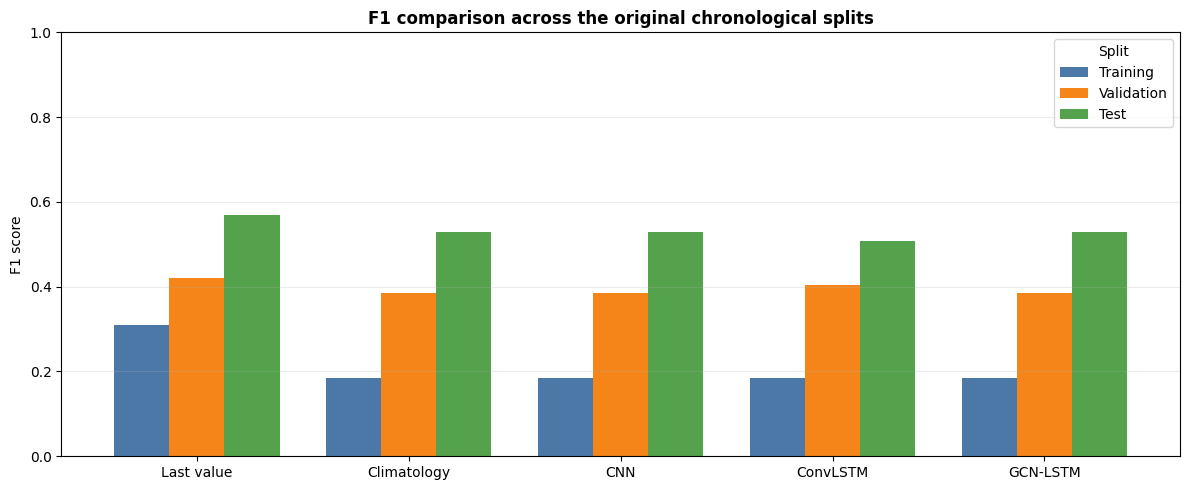

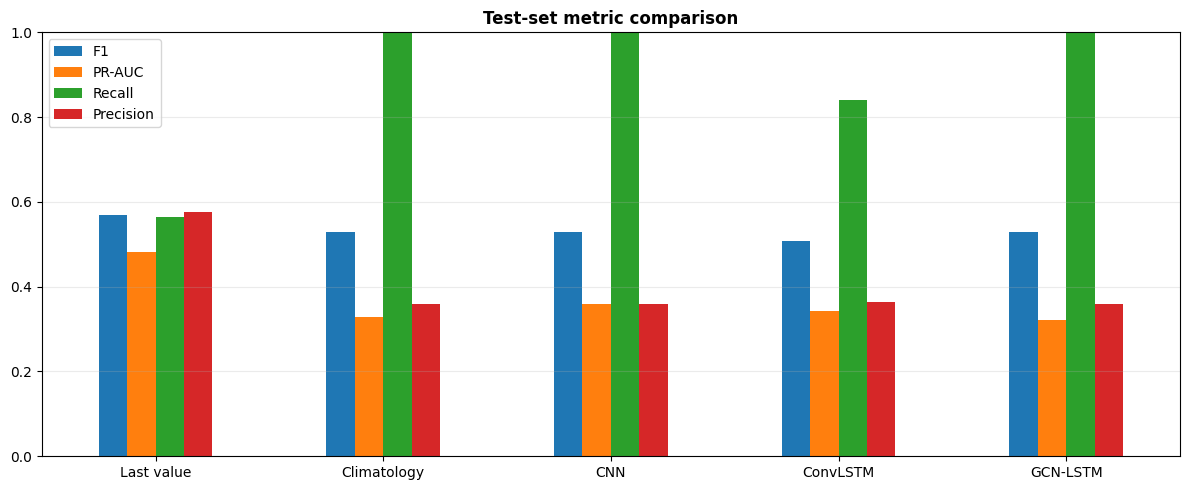

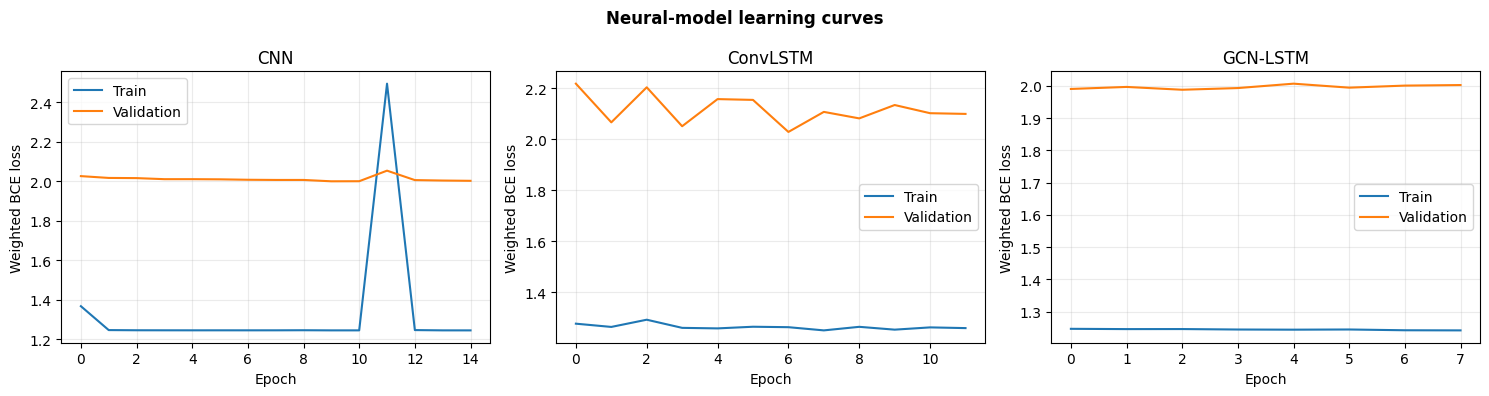

In [23]:
# Required grouped bar chart: training, validation, and test F1 for every model.
model_order = ["Last value", "Climatology", "CNN", "ConvLSTM", "GCN-LSTM"]
split_order = ["Training", "Validation", "Test"]
f1_table = comparison_results.pivot(index="Model", columns="Split", values="F1").reindex(model_order)
ax = f1_table.reindex(columns=split_order).plot.bar(figsize=(12, 5), width=0.78,
                                                     color=["#4C78A8", "#F58518", "#54A24B"])
ax.set_title("F1 comparison across the original chronological splits", weight="bold")
ax.set_xlabel("")
ax.set_ylabel("F1 score")
ax.set_ylim(0, 1)
ax.legend(title="Split")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Test-set comparison gives a second, complementary view of imbalanced-map quality.
test_metrics = comparison_results.query("Split == 'Test'").set_index("Model").reindex(model_order)
ax = test_metrics[["F1", "PR-AUC", "Recall", "Precision"]].plot.bar(figsize=(12, 5))
ax.set_title("Test-set metric comparison", weight="bold")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Learning curves exist only for trainable neural models.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, (name, history) in zip(axes, all_histories.items()):
    ax.plot(history["train_loss"], label="Train")
    ax.plot(history["val_loss"], label="Validation")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Weighted BCE loss")
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle("Neural-model learning curves", weight="bold")
plt.tight_layout()
plt.show()


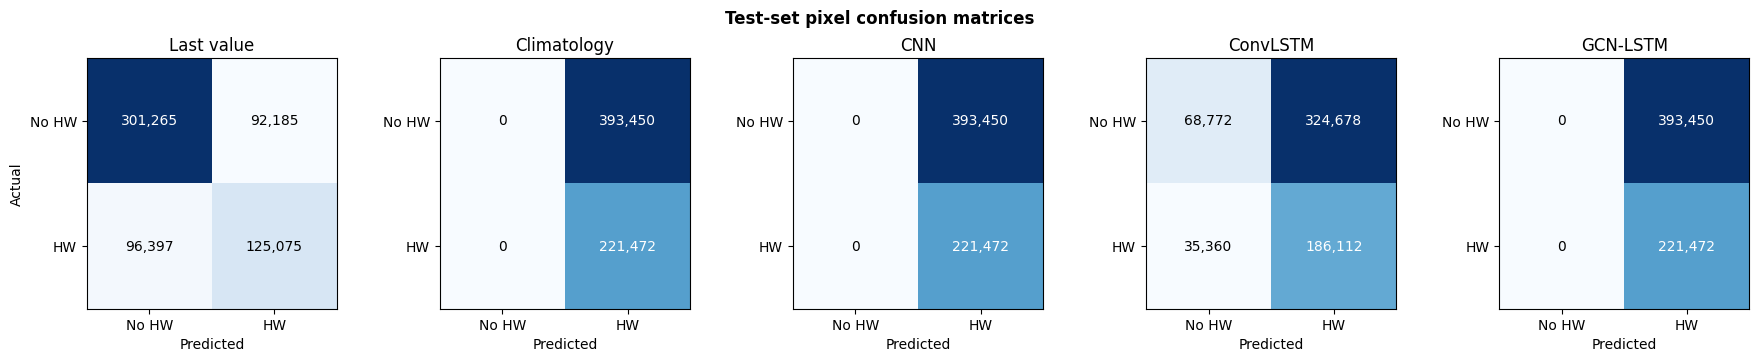

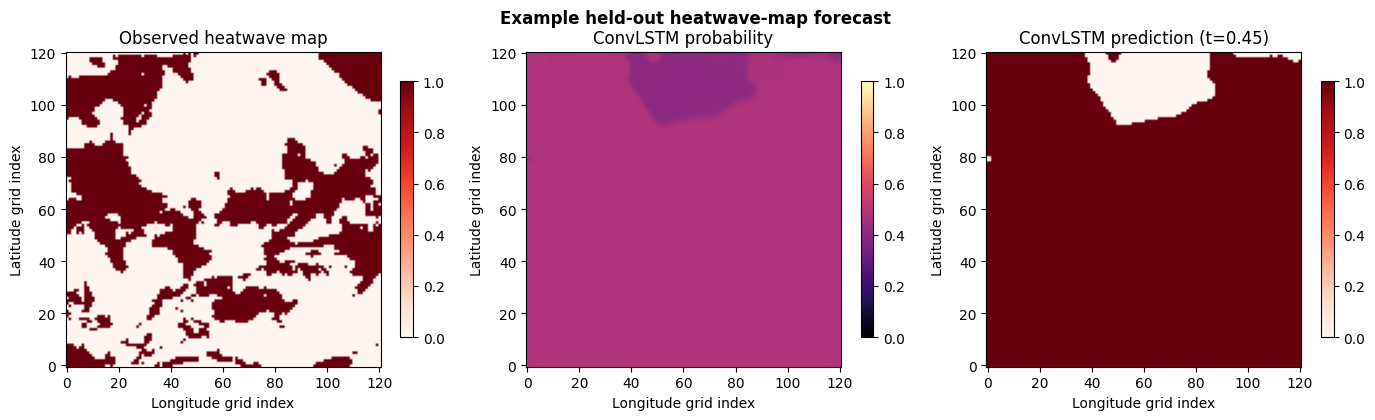

In [24]:
# Test confusion matrices: thresholds were chosen on validation only.
fig, axes = plt.subplots(1, len(model_order), figsize=(18, 3.5))
for ax, name in zip(axes, model_order):
    prob, truth = saved_predictions[name]["Test"]
    threshold = float(comparison_results.query("Model == @name and Split == 'Test'")["Threshold"].iloc[0])
    cm = confusion_matrix(truth.reshape(-1), (prob.reshape(-1) >= threshold).astype(int), labels=[0, 1])
    im = ax.imshow(cm, cmap="Blues")
    for row in range(2):
        for col in range(2):
            ax.text(col, row, f"{cm[row, col]:,}", ha="center", va="center",
                    color="white" if cm[row, col] > cm.max() / 2 else "black")
    ax.set_title(name)
    ax.set_xticks([0, 1], ["No HW", "HW"])
    ax.set_yticks([0, 1], ["No HW", "HW"])
    ax.set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
fig.suptitle("Test-set pixel confusion matrices", weight="bold")
plt.tight_layout()
plt.show()

# One visual map forecast; choose ConvLSTM because it preserves the full time/spatial structure.
selected_model = "ConvLSTM"
sample_index = min(0, len(y_test) - 1)
prob, truth = saved_predictions[selected_model]["Test"]
threshold = float(comparison_results.query("Model == @selected_model and Split == 'Test'")["Threshold"].iloc[0])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
panels = [
    (truth[sample_index], "Observed heatwave map", "Reds", 0, 1),
    (prob[sample_index], "ConvLSTM probability", "magma", 0, 1),
    ((prob[sample_index] >= threshold).astype(int), f"ConvLSTM prediction (t={threshold:.2f})", "Reds", 0, 1),
]
for ax, (data, title, cmap, vmin, vmax) in zip(axes, panels):
    image = ax.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax, origin="lower")
    ax.set_title(title)
    ax.set_xlabel("Longitude grid index")
    ax.set_ylabel("Latitude grid index")
    fig.colorbar(image, ax=ax, shrink=0.8)
fig.suptitle("Example held-out heatwave-map forecast", weight="bold")
plt.tight_layout()
plt.show()


## Architecture references

- Jacques-Dumas, V., et al. (2022), *Deep neural networks to predict heatwaves*.
  The 12×12 / 9×9 CNN backbone used above is a map-output adaptation of its spatial
  CNN architecture: https://doi.org/10.3389/fclim.2022.789641
- Pellicer-Valero, O. J., et al. (2025), *Explainable Earth Surface Forecasting Under
  Extreme Events*. The three-cell 3×3 ConvLSTM structure used above follows this model
  family: https://doi.org/10.1029/2024EF005446

The reported results remain valid only for the original notebook's labels and split.
Replace the labels later with the real GHWR labels before making scientific claims.
